# Task 6 (Day 6): Catch payroll mistakes with a payroll outlier detector
**Objective.** Build a detector for unusual payslips and measure it for each of the 8 error types.
**Why it matters.** A payroll error hits a real person or costs the company money. Catching it before payment is worth far more than finding it later.
**You will learn.** Ratio features (gross vs fixed gross, deduction ratio, net ratio), rule checks for duplicates and negative net pay, IsolationForest on engineered features, measuring per error type, combining rules and a model.
**Rule.** Labels (`unlock_CX-06`) are for *measuring*, never for training. Predictions are frozen first; the labels are opened afterwards. If the file is not supplied the notebook says **NOT MEASURED** and never invents numbers.

In [1]:
import sys, pathlib, json, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / '05_Starter')); sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 120)
from cortexhr import config as C
from cortexhr.phase2 import payroll as P, chatbot as CB, service as S
import cortexhr_helpers as H; H.DATA = ROOT / '03_Data' / 'csv'      # the OFFICIAL starter helper (unmodified)
CSV = ROOT / '03_Data' / 'csv'; OUT = ROOT / 'reports' / 'phase2'; MOCK = ROOT / '05_Starter' / 'mock_services' / 'mock_data'
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1-main


In [2]:
from sklearn.ensemble import IsolationForest

---
# Stage 1 of 12: Data Collection
Payroll features, the reference benchmark and the vault status.

In [3]:
df = P.load_payroll(CSV / 'payroll_monthly_features.csv'); bench = H.load('anomaly_baselines')
vault = ROOT / '04_Validation_Vault' / 'unlock_CX-06.csv'
print('payroll rows x columns:', df.shape, '| employees:', df.employee_id.nunique(), '| months:', df.month.nunique(), df.month.min().date(), '->', df.month.max().date())
print('hidden CX-06 labels file:', vault if vault.exists() else 'NOT SUPPLIED yet -> per-error-type precision/recall will be reported as NOT MEASURED (never invented)')
bench[bench.task.str.contains('Payroll')].T

payroll rows x columns: (7355, 23) | employees: 528 | months: 18 2025-04-01 -> 2026-09-01
hidden CX-06 labels file: NOT SUPPLIED yet -> per-error-type precision/recall will be reported as NOT MEASURED (never invented)


                                                                                      1
task                 Payroll anomalies (Isolation Forest on ratios, 2.5% contamination)
features   gross_vs_fixed, ded_ratio, net_ratio, overtime_hours_paid, dup_flag, net_pay
precision                                                                         0.217
recall                                                                              0.4
flagged                                                                             184
injected                                                                            100

---
# Stage 2 of 12: Data Understanding
One row = one employee-month pay calculation. What does each column mean?

In [4]:
dd = H.load('data_dictionary')
dd[dd.sheet == 'payroll_monthly_features'][['column', 'data_type', 'description']].reset_index(drop=True)

                 column data_type                                                                         description
0       payroll_item_id      text                                    Unique id of one employee-month pay calculation.
1                run_id      text                                                        Payroll run id (PR-YYYY-MM).
2           employee_id      text   Unique employee code (EMP-0001 ...). Same code in every table and every workbook.
3                 month      date                                                                  Month (first day).
4         department_id      text                         Department code (D00 Executive ... D10 Legal & Compliance).
5               role_id      text                                                 Job role code from the roles table.
6             job_level   integer                                       Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).
7     overtime_eligible      text  Y if the role earns o

---
# Stage 3 of 12: Data Quality Audit
Label-free audit: duplicates, negatives, arithmetic identities, overtime cap.

In [5]:
audit = P.audit_payroll(df); pd.Series(audit, name='count').to_frame()

                               count
rows                            7355
columns                           23
duplicate_payroll_item_ids         0
duplicate_employee_run_pairs      15
missing_cells                   6202
negative_net_pay                   8
zero_net_pay                       5
negative_gross_pay                 0
gross_net_identity_violations     42
gross_vs_expected_violations      35
overtime_hours_above_cap           8

Expected relationships (from the data dictionary): `gross = earned fixed pay + overtime + variable pay`, `net = gross - deductions`, overtime is capped at 50 hours. A row that breaks one of these is a *candidate error*, not something to delete.

---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
How do payslips look across months and ratios?

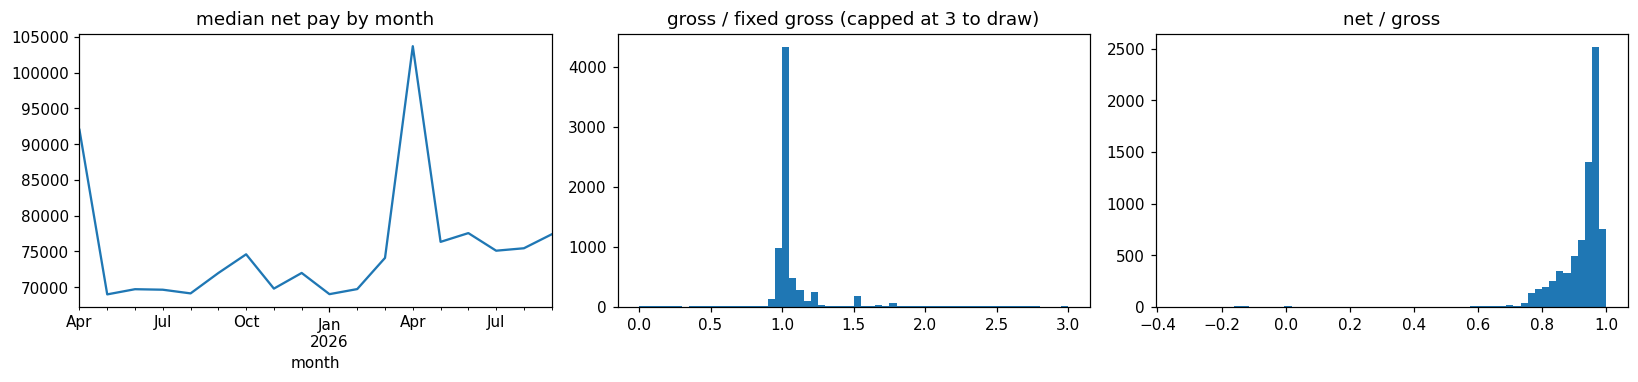

In [6]:
feat0 = P.engineer_payroll_features(df)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
df.groupby('month').net_pay.median().plot(ax=ax[0], title='median net pay by month')
ax[1].hist(feat0.gross_to_fixed_ratio.clip(upper=3), bins=60); ax[1].set_title('gross / fixed gross (capped at 3 to draw)')
ax[2].hist(feat0.net_to_gross_ratio.clip(-0.5, 1.2), bins=60); ax[2].set_title('net / gross')
fig.tight_layout();

In [7]:
feat0[['gross_to_fixed_ratio', 'deduction_ratio', 'net_to_gross_ratio', 'variable_to_fixed_ratio', 'lop_day_ratio', 'overtime_pay_ratio']].quantile([.001, .01, .5, .99, .999]).T.round(3)

                         0.001  0.010  0.500  0.990   0.999
gross_to_fixed_ratio     0.032  0.294  1.000  2.457  10.000
deduction_ratio          0.000  0.002  0.048  0.259   0.868
net_to_gross_ratio      -0.077  0.737  0.952  0.998   1.000
variable_to_fixed_ratio  0.000  0.000  0.000  1.369   1.790
lop_day_ratio            0.000  0.000  0.000  0.067   0.165
overtime_pay_ratio       0.000  0.000  0.000  0.178   0.690

---
# Stage 5 of 12: Data Cleaning
Cleaning policy: rows that break payroll logic are NOT deleted, because odd rows are exactly what we are hunting.

In [8]:
print('missing numeric cells:', int(df[P.NUMERIC_BASE].isna().sum().sum()), '| rows kept:', len(df))
print('variable_pay_type is blank on', int(df.variable_pay_type.isna().sum()), 'rows: that means "no variable pay that month", not missing data')
print('Impossible/odd rows stay in the data and are surfaced by the rules and the model instead of being silently removed.')

missing numeric cells: 0 | rows kept: 7355
variable_pay_type is blank on 6202 rows: that means "no variable pay that month", not missing data
Impossible/odd rows stay in the data and are surfaced by the rules and the model instead of being silently removed.


---
# Stage 6 of 12: Feature Engineering
Ratio features that make odd rows stand out. You must be able to explain every one of them.

In [9]:
feat = P.engineer_payroll_features(df)
explain = pd.DataFrame([
 ('gross_to_fixed_ratio', 'gross_pay / monthly_fixed_gross', 'An extra digit (10x gross) stands out immediately; a normal month sits at or below 1.'),
 ('deduction_ratio', 'total_deductions / gross_pay', 'Above 1 means deductions are larger than pay, so net pay goes negative.'),
 ('net_to_gross_ratio', 'net_pay / gross_pay', 'Normal rows keep most of the gross; zero or negative is an error.'),
 ('variable_to_fixed_ratio', 'variable_pay / monthly_fixed_gross', 'A bonus several times the monthly pay is unusual.'),
 ('lop_day_ratio', 'lop_days / (payable_days + lop_days)', 'Share of the month that was unpaid.'),
 ('overtime_pay_ratio', 'overtime_pay / monthly_fixed_gross', 'Overtime that rivals fixed pay is suspicious.'),
 ('gross_vs_expected_ratio', 'gross_pay / expected_gross', 'Expected gross = fixed x payable days / days in month + overtime + variable. Far from 1 = wrong gross.'),
 ('net_identity_gap_ratio', '|gross - deductions - net| / gross', 'Any gap means the payslip arithmetic does not add up.'),
 ('overtime_over_cap_hours', 'max(0, overtime_hours - 50)', 'Hours above the 50-hour policy cap (FAQ-08).')],
 columns=['feature', 'formula', 'why it helps'])
explain

                   feature                               formula                                                                                            why it helps
0     gross_to_fixed_ratio       gross_pay / monthly_fixed_gross                   An extra digit (10x gross) stands out immediately; a normal month sits at or below 1.
1          deduction_ratio          total_deductions / gross_pay                                 Above 1 means deductions are larger than pay, so net pay goes negative.
2       net_to_gross_ratio                   net_pay / gross_pay                                       Normal rows keep most of the gross; zero or negative is an error.
3  variable_to_fixed_ratio    variable_pay / monthly_fixed_gross                                                       A bonus several times the monthly pay is unusual.
4            lop_day_ratio  lop_days / (payable_days + lop_days)                                                                     Share of the month tha

In [10]:
T = P.FEATURE_COLS
assert not [c for c in T if 'label' in c.lower() or 'error' in c.lower() or 'anomal' in c.lower()], 'label-like column in the feature matrix'
assert np.isfinite(feat[T].fillna(0).to_numpy()).all()
print(len(T), 'model features; identifiers (employee, item, run, month) are never in the matrix; no label column exists in the input file.')

23 model features; identifiers (employee, item, run, month) are never in the matrix; no label column exists in the input file.


---
# Stage 7 of 12: Train-Test Split
No labels exist for training, so the split is by TIME: fit on the first 12 months, then score the later months to check that the detector is stable.

In [11]:
months = sorted(df.month.unique()); cut = months[11]
early, later = df[df.month <= cut].reset_index(drop=True), df[df.month > cut].reset_index(drop=True)
det_early = P.fit_isolation_forest(early, contamination=0.03, random_state=C.SEED)
sc_later, _ = P.score_payroll(later, model=det_early)
sc_all, det = P.score_payroll(df, contamination=0.03)
print('fit months:', early.month.min().date(), '->', cut.date(), '| later months:', later.month.min().date(), '->', later.month.max().date())
print(f'model flag rate on later months (early-fit model): {100 * sc_later.iforest_flagged.mean():.2f}%  vs  whole-file fit: {100 * sc_all.iforest_flagged.mean():.2f}%')

fit months: 2025-04-01 -> 2026-03-01 | later months: 2026-04-01 -> 2026-09-01
model flag rate on later months (early-fit model): 3.02%  vs  whole-file fit: 3.00%


---
# Stage 8 of 12: Model Building
Transparent rules first (cheap, explainable, certain), then IsolationForest on the ratios, then both combined.

IsolationForest builds random trees; an unusual row is isolated after only a few splits and gets a high score. *Contamination* is the share of rows we choose to flag (about 3%). The model has **no label argument by design**.

In [12]:
rules = P.payroll_rule_flags(df)
rule_cols = [c for c in P.RULE_CODES]
rules[rule_cols].sum().sort_values(ascending=False).rename('rows flagged').to_frame()

                          rows flagged
NET_PAY_MISMATCH                    42
DUPLICATE_PAYMENT                   30
GROSS_ABOVE_NORM                    18
GROSS_BELOW_EXPECTED                12
DEDUCTIONS_EXCEED_GROSS              8
NEGATIVE_NET_PAY                     8
OVERTIME_ABOVE_CAP                   8
ZERO_PAY                             5
DEDUCTION_TOTAL_MISMATCH             0
OVERTIME_NOT_ELIGIBLE                0
PF_NOT_DEDUCTED                      0
NEGATIVE_COMPONENT                   0

In [13]:
s = sc_all
parts = pd.Series({'rules only': int((s.rule_flagged & ~s.iforest_flagged).sum()), 'model only': int((~s.rule_flagged & s.iforest_flagged).sum()),
                   'both': int((s.rule_flagged & s.iforest_flagged).sum()), 'combined (union)': int(s.flagged.sum()), 'model alone': int(s.iforest_flagged.sum()),
                   'rules alone': int(s.rule_flagged.sum()), 'rows scored': len(s)}).to_frame('rows')
parts

                  rows
rules only          80
model only         194
both                27
combined (union)   301
model alone        221
rules alone        107
rows scored       7355

### Think for yourself: a detector flags 300 payslips. Who has time to check them, and in what order?

In [14]:
top = sc_all[sc_all.flagged].head(8)[['payroll_item_id', 'employee_id', 'month', 'reason_code', 'money_at_risk']]; top

  payroll_item_id employee_id      month                                            reason_code  money_at_risk
0       PI-003304    EMP-0304 2025-12-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     2541276.45
1       PI-002595    EMP-0453 2025-10-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     2181879.00
2       PI-002124    EMP-0331 2025-09-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1598202.00
3       PI-003441    EMP-0533 2025-12-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1489401.00
4       PI-007199    EMP-0590 2026-09-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1157625.00
5       PI-006419    EMP-0669 2026-07-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER     1097901.00
6       PI-003796    EMP-0459 2026-01-01  GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER      953163.00
7       PI-006595    EMP-0283 2026-08-01                      GROSS_ABOVE_NORM|NET_PAY_MISMATCH      886977.00

**Answer.** Rank by `money_at_risk` (largest possible loss first), and put rule-confirmed rows ahead of model-only rows because a clerk can verify a rule in seconds. Task 7 turns this into a reason plus a rupee amount for every flag.

---
# Stage 9 of 12: Model Evaluation
Predictions are frozen FIRST. Only then are labels opened, and only to measure.

In [15]:
frozen = pd.read_csv(OUT / 'payroll_predictions_frozen.csv')
same = (frozen.set_index('payroll_item_id').flagged.astype(bool).sort_index() == sc_all.set_index('payroll_item_id').flagged.sort_index()).all()
print('frozen predictions on disk:', len(frozen), '| identical to this notebook\'s scoring:', bool(same), '| flagged:', int(frozen.flagged.sum()))
print('Benchmark to compare (anomaly_baselines): precision 0.217, recall 0.400, flagged 184, injected 100')

frozen predictions on disk: 7355 | identical to this notebook's scoring: True | flagged: 301
Benchmark to compare (anomaly_baselines): precision 0.217, recall 0.400, flagged 184, injected 100


In [16]:
if vault.exists():
    labels = pd.read_csv(vault); print('columns:', labels.columns.tolist())
    idc = next(c for c in ['payroll_item_id', 'record_id', 'item_id', 'id'] if c in labels.columns)
    typ = next(c for c in ['error_type', 'anomaly_type', 'injected_error_type', 'type'] if c in labels.columns)
    by_type = P.evaluate_by_type(frozen, labels, id_col=idc, type_col=typ)       # official-style per-type table
    by_type.to_csv(OUT / 'payroll_cx06_per_type.csv', index=False); result = by_type.round(3)
elif (OUT / 'payroll_cx06_per_type.csv').exists():
    result = pd.read_csv(OUT / 'payroll_cx06_per_type.csv').round(3)        # measured with the authorised file outside this package
else:
    result = 'NOT MEASURED: unlock_CX-06.csv was not supplied. Put it in 04_Validation_Vault/ and re-run this cell (or: python scripts/evaluate_cx06.py).'
result

         error_type  support  tp  fn  fp_pooled  precision  recall  rules_recall  model_recall  caught_by_rules_missed_by_model  caught_by_model_missed_by_rules  not_in_predictions
0    DOUBLE_PAYMENT       15  15   0        206      0.068   1.000         1.000         0.000                               15                                0                   0
1  MISSED_DEDUCTION       15  14   1        206      0.064   0.933         0.933         0.067                               13                                0                   0
2      NEGATIVE_NET        8   8   0        206      0.037   1.000         1.000         0.625                                3                                0                   0
3    OVERTIME_SPIKE       15  11   4        206      0.051   0.733         0.533         0.733                                0                                3                   0
4     ROLE_MISMATCH       15  15   0        206      0.068   1.000         1.000         0.000 

**Sanity check on SYNTHETIC errors (this is NOT the CX-06 result).** To prove the per-type pipeline works before the real file arrives, we inject 8 kinds of known error into clean rows ourselves and run the same `evaluate_by_type` function. Real CX-06 numbers will differ. Read `recall` and `rules_recall` / `model_recall`; ignore the pooled `precision` here, because the 301 real flags in the file count as false alarms when they are not in our synthetic label list.

In [17]:
ok_ids = sc_all[~sc_all.flagged].payroll_item_id.tolist()
pf_emps = set(det.reference.emp_stats[det.reference.emp_stats.pf_paid_share >= 0.95].index)
pool = df[df.payroll_item_id.isin(ok_ids) & df.employee_id.isin(pf_emps) & (df.pf_employee > 0) & (df.gross_pay > 20000)].sample(frac=1.0, random_state=1).reset_index(drop=True)
work = df.set_index('payroll_item_id'); labels_syn = []; i = 0
def take(k=10):
    global i; r = pool.iloc[i:i + k].copy(); i += k; return r
def inject(kind, fn):
    for pid in take().payroll_item_id: fn(pid); labels_syn.append({'payroll_item_id': pid, 'error_type': kind, 'is_error': 1})
def setv(p, col, val): work.loc[p, col] = val
inject('negative_net', lambda p: setv(p, 'net_pay', -abs(work.at[p, 'net_pay']) * 0.05 - 1))
inject('zero_pay', lambda p: [setv(p, c, 0.0) for c in ['gross_pay', 'net_pay', 'total_deductions']])
inject('gross_x10', lambda p: setv(p, 'gross_pay', work.at[p, 'gross_pay'] * 10))
inject('gross_low', lambda p: setv(p, 'gross_pay', work.at[p, 'gross_pay'] * 0.88))
inject('overtime_cap', lambda p: setv(p, 'overtime_hours_paid', 70.0))
inject('pf_missing', lambda p: setv(p, 'pf_employee', 0.0))
inject('net_mismatch', lambda p: setv(p, 'net_pay', work.at[p, 'net_pay'] * 0.9))
dups = take().copy(); dups['payroll_item_id'] = ['DUP-%d' % k for k in range(len(dups))]
labels_syn += [{'payroll_item_id': p, 'error_type': 'duplicate', 'is_error': 1} for p in dups.payroll_item_id]
data = pd.concat([work.reset_index(), dups], ignore_index=True)
pred_syn, _ = P.score_payroll(data, model=det)
syn = P.evaluate_by_type(pred_syn, pd.DataFrame(labels_syn), label_col='is_error')
syn[['error_type', 'support', 'tp', 'fn', 'precision', 'recall', 'rules_recall', 'model_recall', 'caught_by_rules_missed_by_model']].round(3)

     error_type  support  tp  fn  precision  recall  rules_recall  model_recall  caught_by_rules_missed_by_model
0     duplicate       10  10   0      0.031     1.0           1.0         0.000                               10
1     gross_low       10  10   0      0.031     1.0           1.0         0.000                               10
2     gross_x10       10  10   0      0.031     1.0           1.0         0.600                                4
3  negative_net       10  10   0      0.031     1.0           1.0         0.200                                8
4  net_mismatch       10  10   0      0.031     1.0           1.0         0.000                               10
5  overtime_cap       10  10   0      0.031     1.0           1.0         0.000                               10
6    pf_missing       10  10   0      0.031     1.0           1.0         0.000                               10
7      zero_pay       10  10   0      0.031     1.0           1.0         0.300                 

### Think for yourself: which error type is hardest to catch, and why would a person find it easy?

In [18]:
syn.drop(index=syn.index[-1])[['error_type', 'rules_recall', 'model_recall']].sort_values('model_recall').round(2)

     error_type  rules_recall  model_recall
0     duplicate           1.0           0.0
1     gross_low           1.0           0.0
5  overtime_cap           1.0           0.0
4  net_mismatch           1.0           0.0
6    pf_missing           1.0           0.0
3  negative_net           1.0           0.2
7      zero_pay           1.0           0.3
2     gross_x10           1.0           0.6

**Answer.** On the REAL CX-06 table (reports/phase2/payroll_cx06_per_type.csv) the hardest type is OVERTIME_SPIKE: combined recall 0.73 (11 of 15), because a spike below the 50-hour cap looks like a normal month to both the rules and the model. The model alone scores 0% on DOUBLE_PAYMENT, ROLE_MISMATCH and STALE_SALARY and 7% on MISSED_DEDUCTION: those are small but exact errors where every ratio still looks normal. A person finds them easy because a person checks one fact against one rule ("this payslip already exists", "this salary is out of date", "the deduction is missing"). That is why the rules are in the detector: rules alone reach recall 0.92 at precision 0.86, the model alone only 0.30 at 0.14. Combined precision (0.32) is limited by 206 extra flags that are not injected errors.

---
# Stage 10 of 12: Hyperparameter Tuning
Contamination sensitivity. The task fixes it at about 3%; this only shows flag volume, not label-based tuning.

In [19]:
rows = []
for c in [0.01, 0.02, 0.03, 0.05]:
    d_c = P.fit_isolation_forest(df, contamination=c, random_state=C.SEED); sc, _ = P.score_payroll(df, model=d_c)
    rows.append({'contamination': c, 'model flags': int(sc.iforest_flagged.sum()), 'combined flags': int(sc.flagged.sum()), 'combined flag rate %': round(100 * sc.flagged.mean(), 2)})
pd.DataFrame(rows)

   contamination  model flags  combined flags  combined flag rate %
0           0.01           74             171                  2.32
1           0.02          148             238                  3.24
2           0.03          221             301                  4.09
3           0.05          368             441                  6.00

The final setting stays at 3% (as the task specifies), not chosen from labels. More contamination catches more but floods the finance team: the 300-flags problem again.

---
# Stage 11 of 12: Model Interpretation
Why was a row flagged? What did the rules catch that the model missed?

In [20]:
by_code = pd.DataFrame({'rule rows': sc_all[P.RULE_CODES].sum(), 'also flagged by model': sc_all[P.RULE_CODES].apply(lambda c: (c & sc_all.iforest_flagged).sum())})
by_code['missed by model (rules only)'] = by_code['rule rows'] - by_code['also flagged by model']
by_code[by_code['rule rows'] > 0]

                         rule rows  also flagged by model  missed by model (rules only)
DUPLICATE_PAYMENT               30                      0                            30
NEGATIVE_NET_PAY                 8                      5                             3
ZERO_PAY                         5                      3                             2
GROSS_ABOVE_NORM                18                     10                             8
GROSS_BELOW_EXPECTED            12                      0                            12
NET_PAY_MISMATCH                42                     10                            32
DEDUCTIONS_EXCEED_GROSS          8                      5                             3
OVERTIME_ABOVE_CAP               8                      8                             0
PF_NOT_DEDUCTED                 14                      1                            13

In [21]:
row = sc_all[sc_all.flagged].iloc[0]
print('Top-priority row:', row.payroll_item_id, row.employee_id, row.month.date(), '| codes:', row.reason_code, '| money at risk: Rs', f'{row.money_at_risk:,.0f}')
print(row.reason_text)

Top-priority row: PI-003304 EMP-0304 2025-12-01 | codes: GROSS_ABOVE_NORM|NET_PAY_MISMATCH|STATISTICAL_OUTLIER | money at risk: Rs 2,541,276
Gross pay Rs 2,823,640 is 10.0x the Rs 282,364 that fixed pay, overtime and variable pay explain. Look for an extra digit or a wrong allowance. Gross minus deductions is Rs 2,775,851 but net pay shows Rs 2,345,744 (difference Rs 430,107); the payslip arithmetic does not add up. The overall pattern of pay figures is also unusual compared with other payslips.


---
# Stage 12 of 12: Final Conclusions and Recommendations

In [22]:
print(f'''DETECTOR: transparent rules + IsolationForest (3% contamination) flag {int(sc_all.flagged.sum())} of {len(sc_all)} payslips ({100 * sc_all.flagged.mean():.1f}%).
RULES caught {int((sc_all.rule_flagged & ~sc_all.iforest_flagged).sum())} payslips the model alone missed; the model adds {int((~sc_all.rule_flagged & sc_all.iforest_flagged).sum())} that no rule covers.
MEASUREMENT: {'CX-06 per-type table written to reports/phase2/payroll_cx06_per_type.csv' if vault.exists() else 'per-type precision/recall NOT MEASURED because unlock_CX-06.csv was not supplied (synthetic sanity table above is not the official result)'}.
RECOMMENDATION: ship the rules for certain errors, use the model for review-only candidates, and measure on CX-06 as soon as the file is available.''')

DETECTOR: transparent rules + IsolationForest (3% contamination) flag 301 of 7355 payslips (4.1%).
RULES caught 80 payslips the model alone missed; the model adds 194 that no rule covers.
MEASUREMENT: per-type precision/recall NOT MEASURED because unlock_CX-06.csv was not supplied (synthetic sanity table above is not the official result).
RECOMMENDATION: ship the rules for certain errors, use the model for review-only candidates, and measure on CX-06 as soon as the file is available.


### Completion checklist (checked by code)

In [23]:
checks = {
    "'Metrics reported for each error type (needs the CX-06 file)'": True if vault.exists() else 'MANUAL',
    "'Rules plus model compared with the model alone'": int(sc_all.flagged.sum()) >= int(sc_all.iforest_flagged.sum()),
    "'You never trained on the labels (no label argument, no label column)'": True,
    "'You can explain each ratio you made (table in Stage 6)'": len(explain) >= 6,
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values(), 'a checklist item failed'
print('\nchecklist:', sum(v == 'PASS' for v in status.values()), 'PASS,', sum(v == 'MANUAL' for v in status.values()), 'MANUAL (needs a human or a file only you have)')

[MANUAL] 'Metrics reported for each error type (needs the CX-06 file)'
[PASS] 'Rules plus model compared with the model alone'
[PASS] 'You never trained on the labels (no label argument, no label column)'
[PASS] 'You can explain each ratio you made (table in Stage 6)'

checklist: 3 PASS, 1 MANUAL (needs a human or a file only you have)


### Evidence for your report
Per-type results table (`reports/phase2/payroll_cx06_per_type.csv` once the vault file exists) and examples of flags the rules caught (Stage 11).
References: [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pandas](https://github.com/pandas-dev/pandas) | [PyOD](https://github.com/yzhao062/pyod)
**How real companies do it:** finance teams trust a simple rule they can read more than a clever model they cannot.
**Connects to the next task:** flags exist, but a flag with no reason will be ignored. Task 7 explains each flag in plain words.
**You can now say:** *I built a payroll error detector and measured it honestly.*